# LSTM exploration

In [1]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms

sys.path.append('../')

from model_recurrent import Model

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-12 14:44:42,029	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-12 14:44:48,157	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
df = pd.read_csv("../full_data.csv")

# Global models

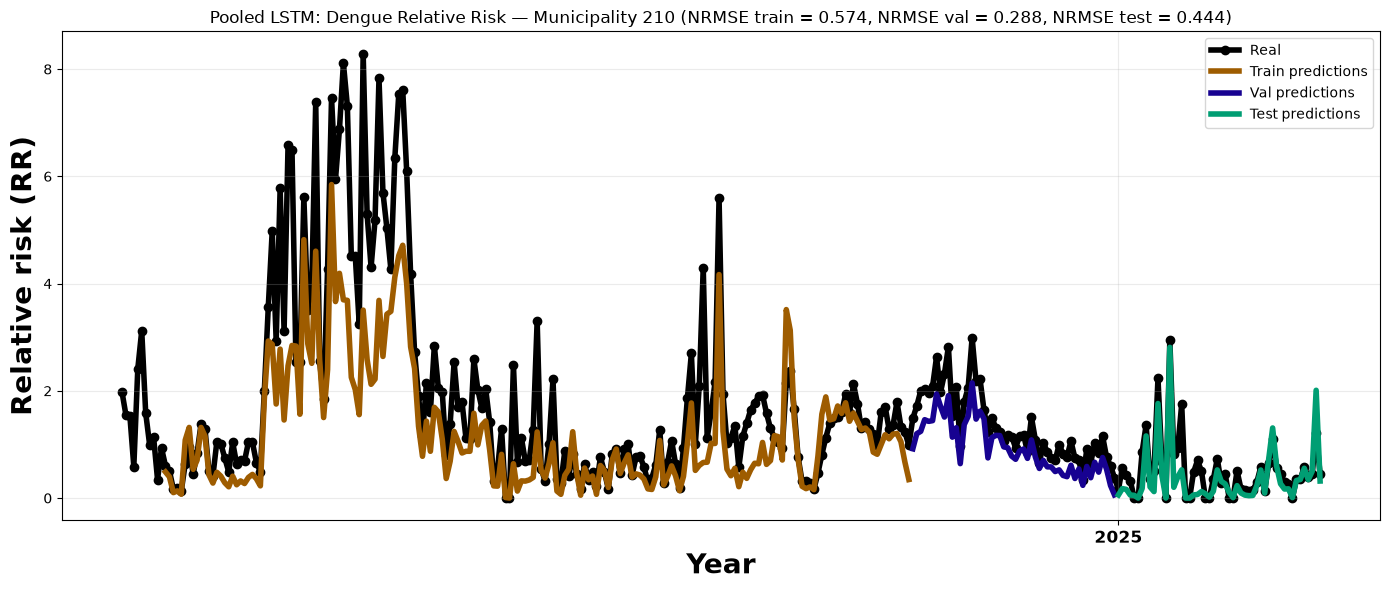

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk — Municipality 210 (NRMSE train = 0.574, NRMSE val = 0.288, NRMSE test = 0.444)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [3]:
model0 = Model(df, "210")
model0.plot_forecast_lstm_full()

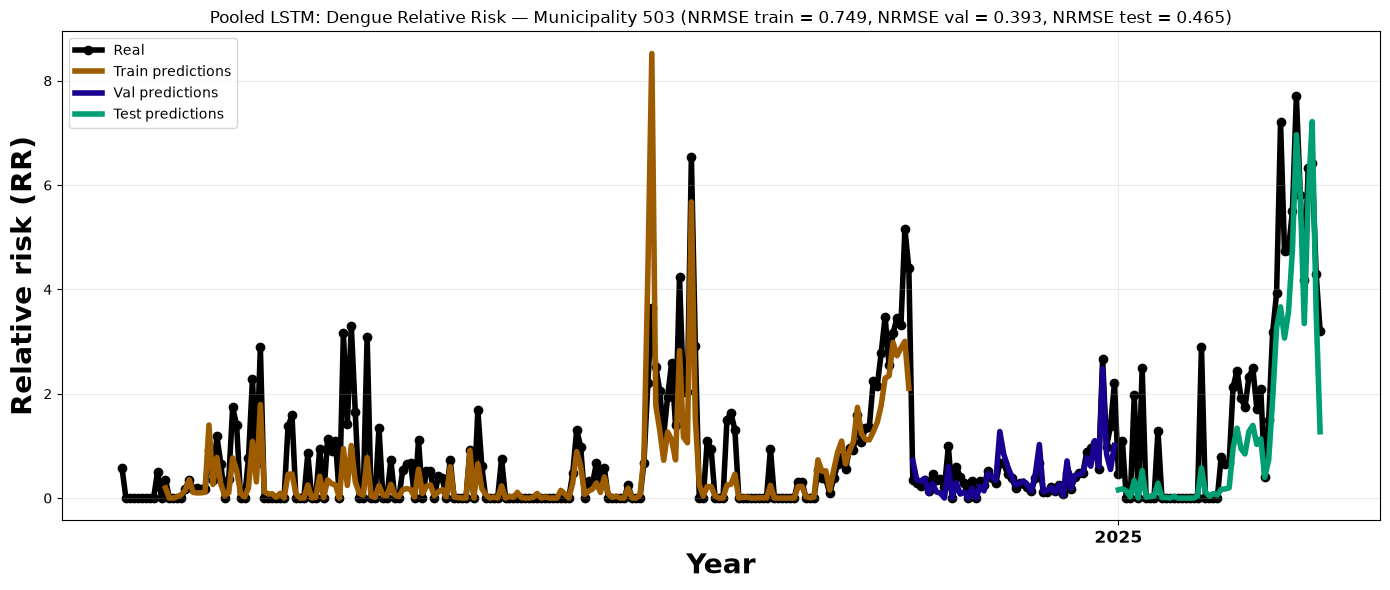

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk — Municipality 503 (NRMSE train = 0.749, NRMSE val = 0.393, NRMSE test = 0.465)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [4]:
model0 = Model(df, "503")
model0.plot_forecast_lstm_full()

# Individual models

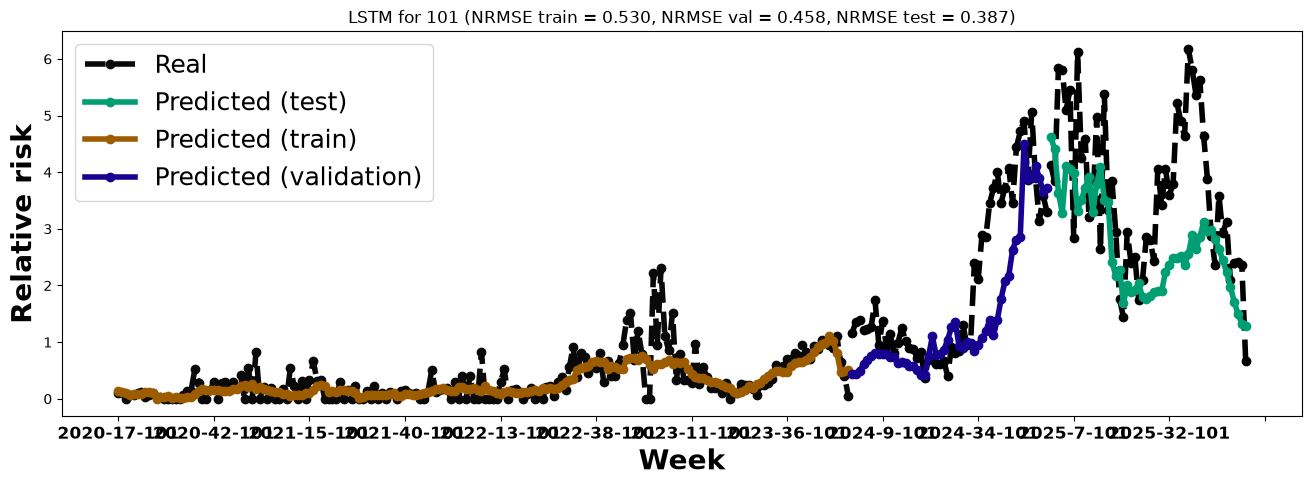

In [8]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()

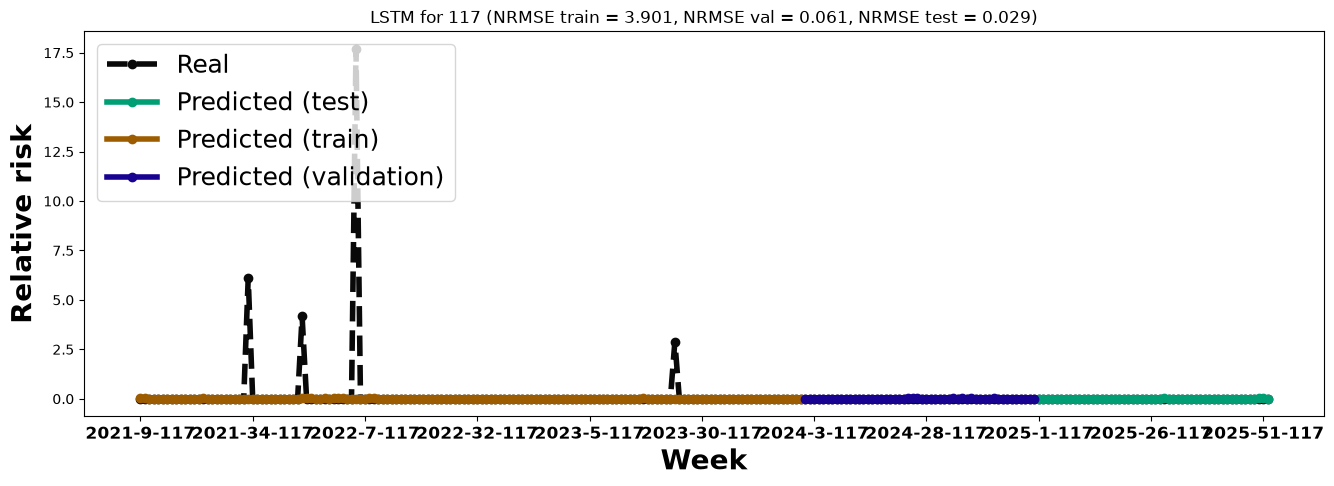

In [9]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()

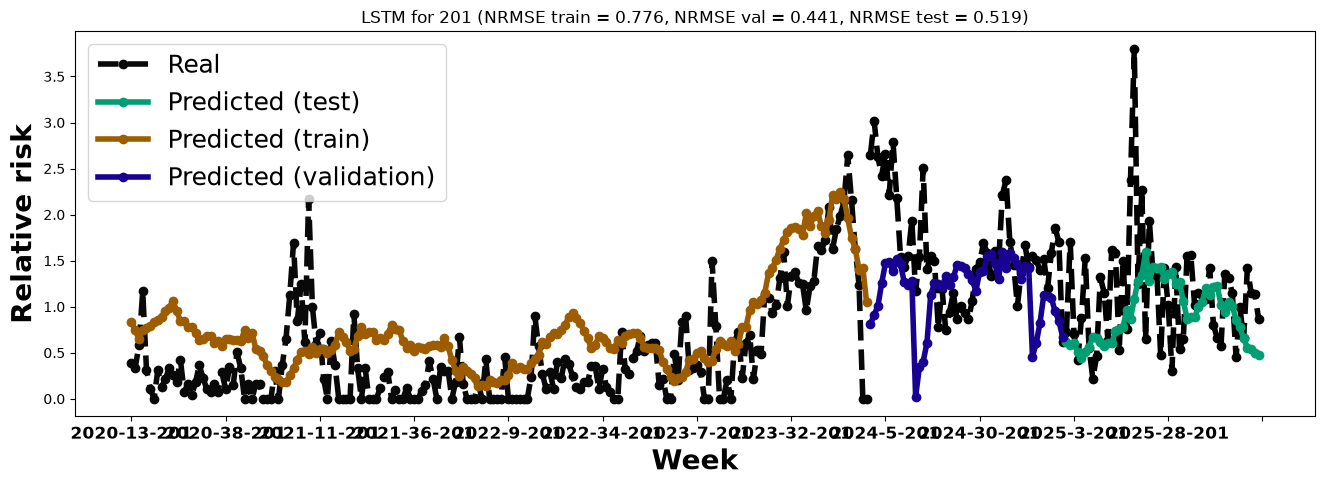

In [10]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()

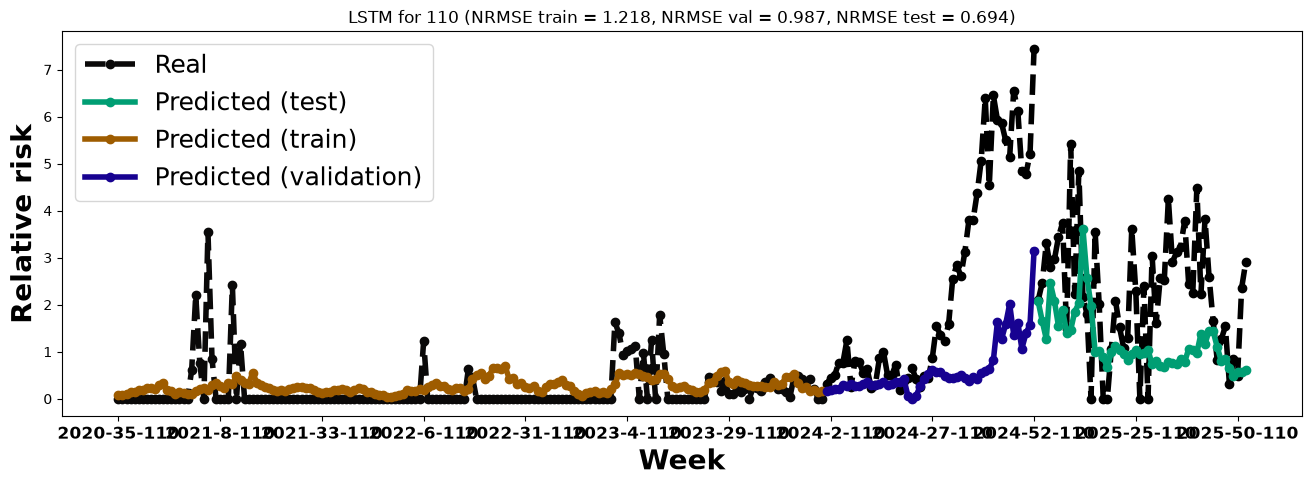

In [11]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()

## Best non-recurrent models

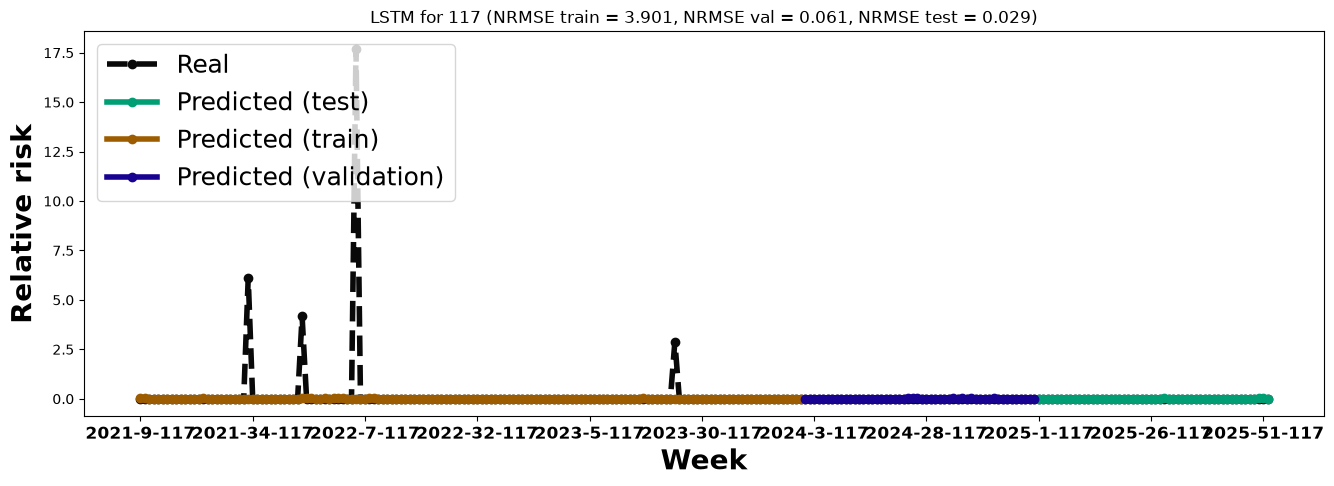

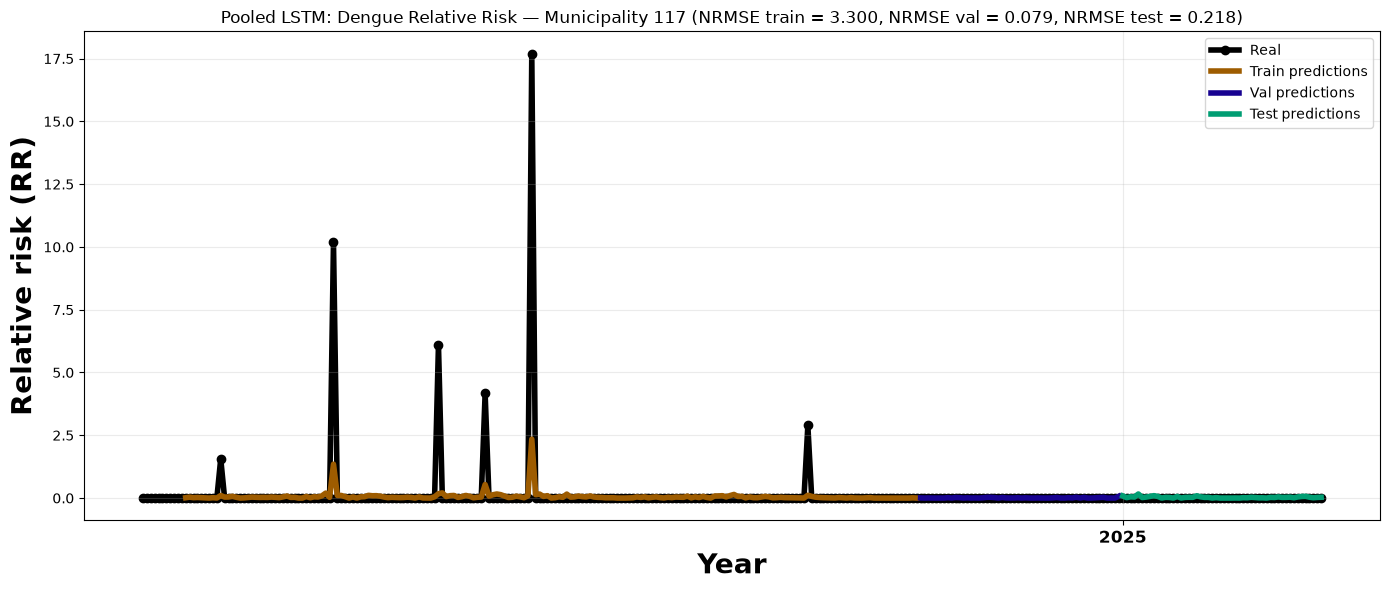

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk — Municipality 117 (NRMSE train = 3.300, NRMSE val = 0.079, NRMSE test = 0.218)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [13]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

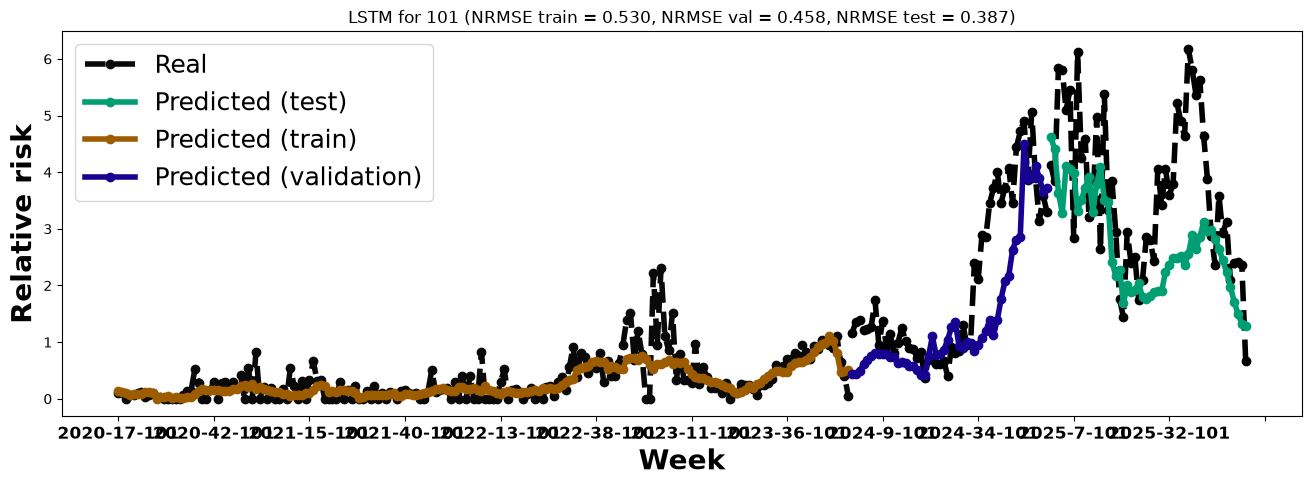

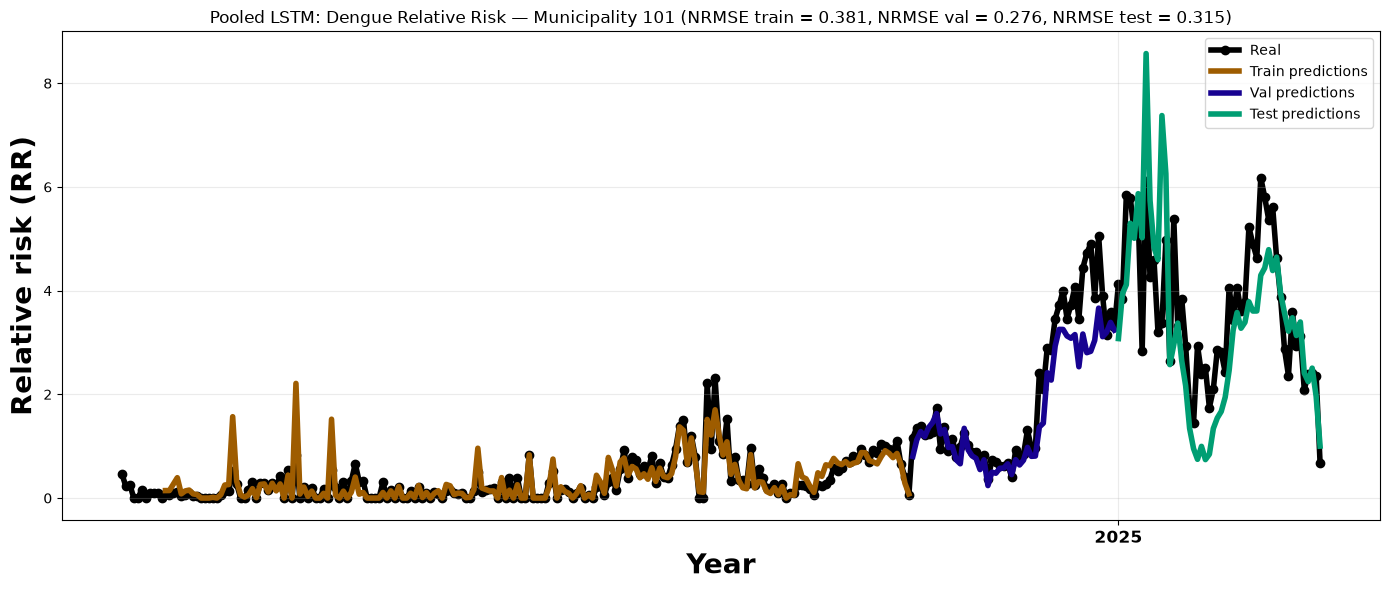

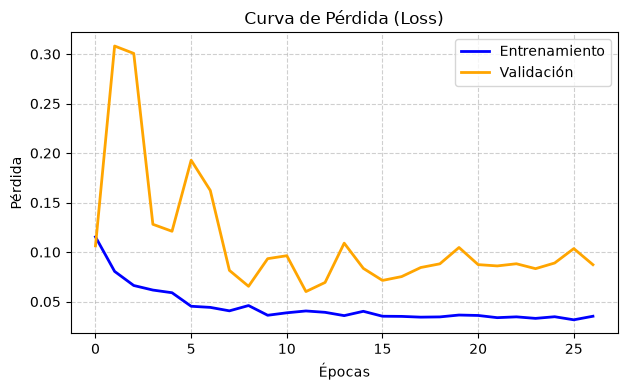

In [14]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()
model0.lstm_eval_plots()

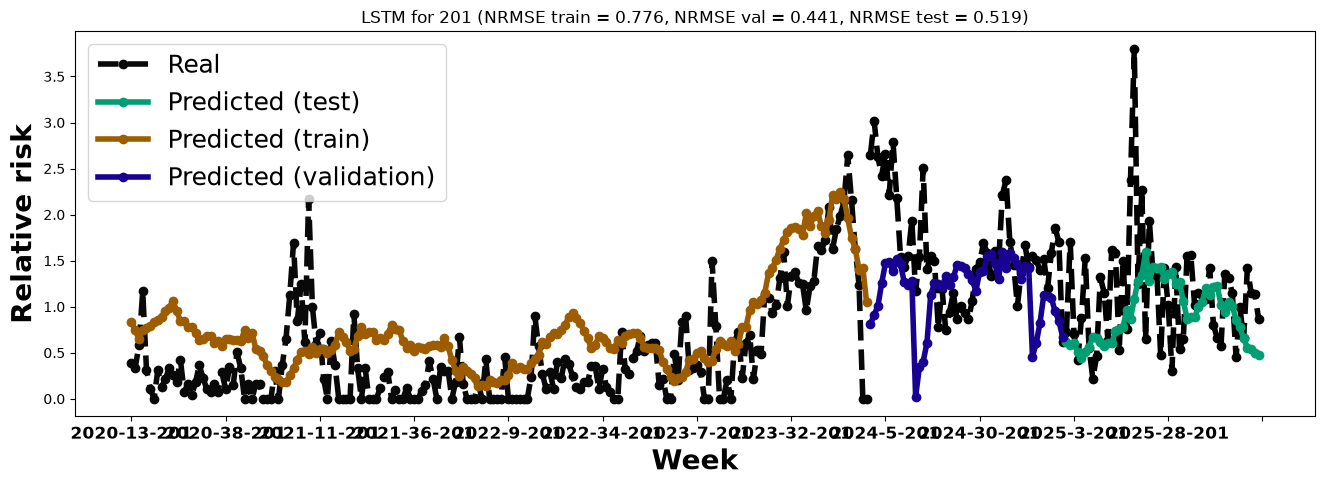

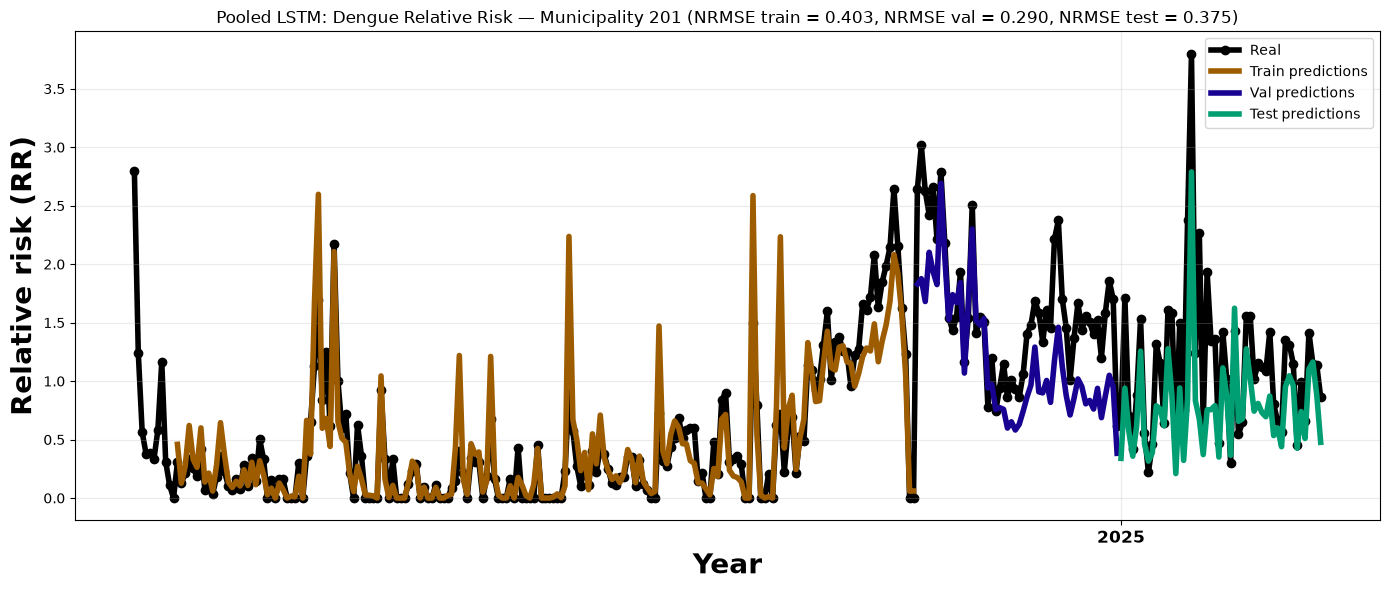

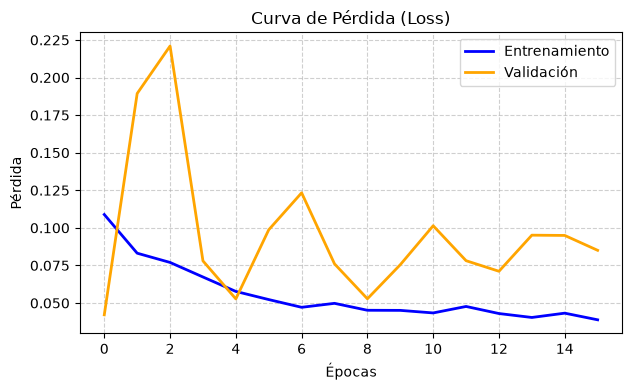

In [15]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()
model0.lstm_eval_plots()

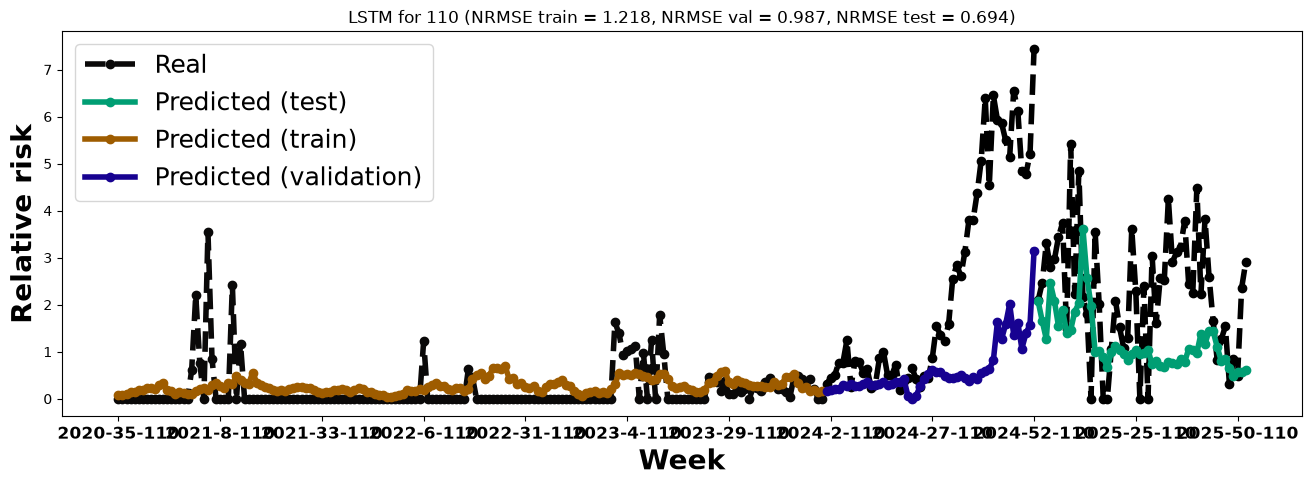

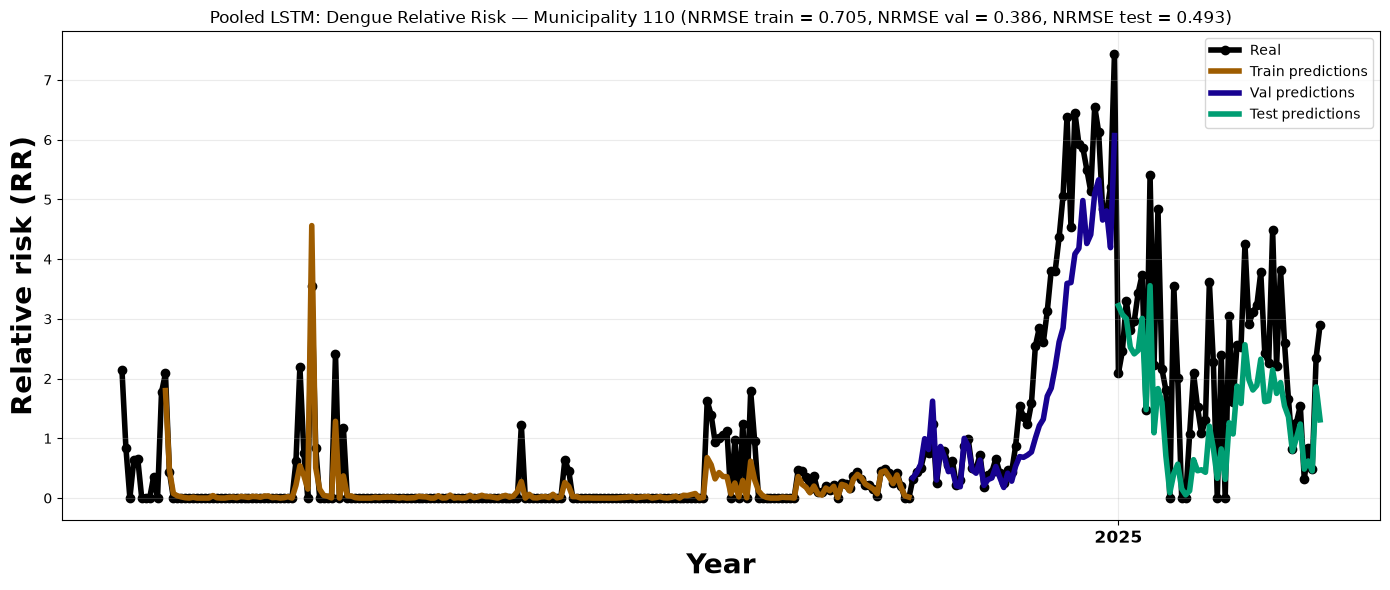

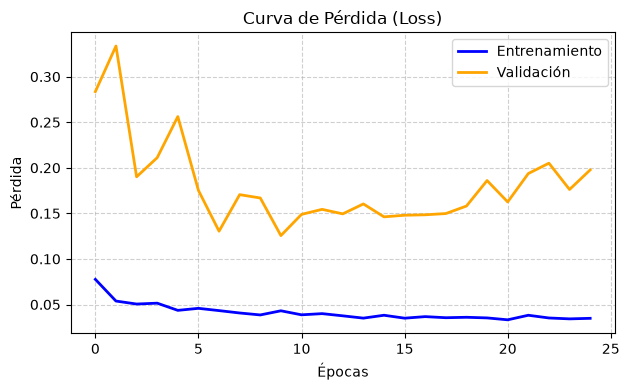

In [16]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()
model0.lstm_eval_plots()

# NRMSE comparison for global and not global models

C:\Windows\Temp\ipykernel_34076\3217968525.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 18, fontweight="bold")


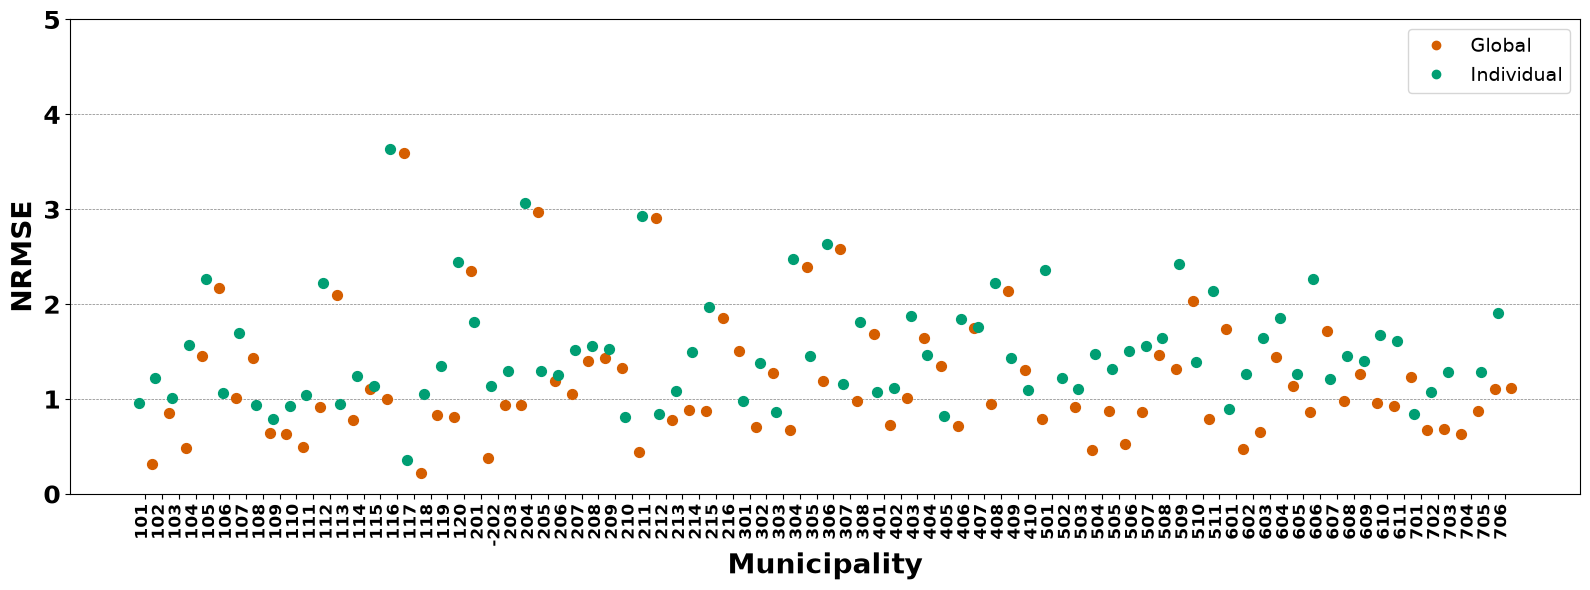

In [21]:
metrics_global = pd.read_csv(f"../data/metrics/nrmse_lstm_full_test.csv")
metrics_individual = pd.read_csv(f"../data/metrics/nrmse_lstm_test.csv")

ind_nrmse = metrics_individual["nodif"]
global_nrmse = metrics_global["nrmse"][1:]

x = np.arange(len(metrics_individual))

fig, ax = plt.subplots(figsize=(16, 6))

cap_width = 0.2

for i, row in metrics_individual.iterrows():

    ax.scatter(
        # Plotting the mean as a point
        x[i],
        ind_nrmse.iloc[i],
        color="#009E73",
        marker="o",
        s=50,
        zorder=4
    )

    x_full = x[i] + 0.8

    ax.scatter(
    # Plotting the individual model NRSME results
        x_full,
        global_nrmse.iloc[i],
        color="#D55E00",
        s=50,
        zorder=3
    )

# Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
ax.set_xticks(x + 0.4)
ax.set_xticklabels(metrics_individual["canton"], rotation=90, ha="right", fontsize = 12, fontweight="bold")
dx = 4 / 72.0  
offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
for label in ax.get_xticklabels():
    label.set_transform(label.get_transform() + offset)

style_handles = [
    # Adding the legend
    Line2D([0], [0], marker="o", color="#D55E00", linestyle="None", label="Global"),    
    Line2D([0], [0], marker = "o", linestyle="None", color="#009E73", label="Individual"),
]
    
ax.set_ylabel("NRMSE", fontsize = 20, fontweight="bold")
ax.set_xlabel("Municipality", fontsize = 20, fontweight="bold")
ax.set_ylim([0, 5])
ax.set_yticklabels(range(0, 6), fontsize = 18, fontweight="bold")
ax.legend(handles=style_handles, fontsize=14, loc="upper right")

plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
plt.tight_layout()
plt.show()